# Día 2 — Validación temporal, estacionariedad y modelos AR/MA

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 05-11-2026 · **Unidades 1 y 2** · Contenidos 1.5, 2.1, 2.2 y 2.3 · **Actividad 1** (20 puntos)

Ayer terminamos con una lección incómoda: el método que ganó en Validation (2024) quedó entre los peores en Test (2025–2026). La causa fue que **decidimos con un solo corte de 12 meses**, y además en un año atípico.

Hoy resolvemos ese problema y preparamos el terreno para los modelos econométricos:

1. **Horizontes de pronóstico:** ¿cuánto empeora un pronóstico cuando miramos más lejos?
2. **Validación con origen móvil:** evaluar muchos cortes en lugar de uno.
3. **Estacionariedad:** la condición que necesitan los modelos ARIMA, y cómo comprobarla con la **prueba ADF**.
4. **Modelos AR y MA:** las dos piezas básicas de ARIMA, primero a mano y luego con statsmodels.
5. **Componentes de ARIMA y SARIMA:** qué significa cada letra de $(p, d, q)(P, D, Q)_s$.

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- qué es el **origen** y el **horizonte** de un pronóstico, y por qué el error suele crecer con el horizonte;
- por qué **una sola validación** puede engañar y cómo funciona la **validación con origen móvil**;
- qué es una serie **estacionaria** y cómo se reconoce en un gráfico;
- qué hace la **diferenciación** y qué pregunta responde la **prueba ADF**;
- cómo funciona un modelo **AR(1)** y un modelo **MA(1)**, y cómo se reconocen en la ACF y la PACF;
- qué significa cada parámetro de un modelo **ARIMA** y **SARIMA**.

## Ruta del día

| Parte | Qué haremos | Herramienta |
|---|---|---|
| 1 | Recuperar la serie y los pronósticos del Día 1 | Pandas |
| 2 | Horizontes de pronóstico | bucle de orígenes |
| 3 | Validación con origen móvil, a mano y con sktime | `ExpandingWindowSplitter`, `evaluate` |
| 4 | Estacionariedad y diferenciación | `rolling`, `diff` |
| 5 | Prueba ADF | `adfuller` |
| 6 | Modelos AR y MA, ACF y PACF | `AutoReg`, `ArmaProcess`, `plot_pacf` |
| 7 | Componentes de ARIMA y SARIMA | — |
| 8 | Actividad 1 y reto | — |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [ ]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib statsmodels scikit-learn sktime

# 0. Librerías

Hoy usamos más herramientas de **statsmodels** y dos de **sktime**. Recordemos el patrón de statsmodels del Día 1: **crear el objeto con los datos → `fit()` → consultar el resultado**. Algunas funciones, como `adfuller` o `acf`, hacen todo en una sola llamada.

| Herramienta | Librería | Para qué |
|---|---|---|
| `adfuller` | statsmodels | prueba de estacionariedad ADF |
| `acf`, `pacf`, `plot_acf`, `plot_pacf` | statsmodels | autocorrelación simple y parcial |
| `AutoReg` | statsmodels | estimar un modelo autorregresivo AR |
| `ArmaProcess` | statsmodels | **simular** series AR y MA con parámetros conocidos |
| `NaiveForecaster` | sktime | los pronósticos simples del Día 1 |
| `ExpandingWindowSplitter`, `evaluate` | sktime | validación con origen móvil |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# statsmodels
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_process import ArmaProcess

# sktime
from sktime.forecasting.naive import NaiveForecaster
from sktime.split import ExpandingWindowSplitter
from sktime.forecasting.model_evaluation import evaluate
from sktime.performance_metrics.forecasting import MeanAbsoluteError

# scikit-learn
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings('ignore', message='.*remember_data.*')

In [ ]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo5_econometria_forecasting_ia/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

# 1. La serie del módulo

**Qué vamos a hacer:** cargar los datos igual que ayer y quedarnos con la inflación mensual desde enero de 2005.

In [4]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')

y = series['ipc_var_mensual'].loc['2005':].dropna()

print(f'{len(y)} meses, de {y.index.min():%b %Y} a {y.index.max():%b %Y}')

260 meses, de Jan 2005 a Aug 2026


**Qué obtuvimos:** los mismos 260 meses del Día 1. Recordemos lo que ya sabemos de esta serie:

| Característica | Lo que encontramos el Día 1 |
|---|---|
| Nivel | media 0.21 % mensual, mucho ruido (desviación 0.37) |
| Tendencia | cambia por etapas: alta en 2008, baja en 2017–2020, sube en 2022 |
| Estacionalidad | meses altos en enero, abril y septiembre |
| Atípicos | concentrados en 2024 |
| Autocorrelación | $r_1 = 0.36$, $r_{12} = 0.28$ |

Y la decisión frágil:

| Periodo | Ganador | MAE |
|---|---|---:|
| Validation 2024 | ingenuo estacional | 0.41 |
| Test 2025–2026 | media histórica | 0.27 |

# 2. Horizontes de pronóstico (1.5)

## 2.1 Origen y horizonte

Todo pronóstico tiene dos coordenadas:

- **Origen** ($t$): el último mes con dato conocido cuando se hace el pronóstico.
- **Horizonte** ($h$): cuántos meses hacia adelante se pronostica.

El pronóstico se escribe $\hat y_{t+h \mid t}$: "el valor del mes $t+h$, pronosticado con la información hasta $t$".

### Ejemplo

Hoy es fines de agosto de 2026 y el último dato es agosto. Si el BCE necesita la inflación de septiembre, octubre y noviembre:

| Mes pronosticado | Origen | Horizonte | Notación |
|---|---|---:|---|
| septiembre 2026 | agosto 2026 | 1 | $\hat y_{\text{sep} \mid \text{ago}}$ |
| octubre 2026 | agosto 2026 | 2 | $\hat y_{\text{oct} \mid \text{ago}}$ |
| noviembre 2026 | agosto 2026 | 3 | $\hat y_{\text{nov} \mid \text{ago}}$ |

**La regla de oro:** el pronóstico de octubre **no puede usar** el dato de septiembre, porque en agosto todavía no existe.

## 2.2 ¿El error crece con el horizonte?

La intuición dice que sí: es más difícil anticipar lo que pasará dentro de un año que el próximo mes. Comprobémoslo.

**Qué vamos a hacer:**

1. Tomar como orígenes todos los meses desde enero de 2015 hasta diciembre de 2023 (108 orígenes).
2. Desde cada origen, pronosticar los 12 meses siguientes con cuatro métodos simples.
3. Promediar el error absoluto de cada método **por horizonte**.

Esto es más trabajo que el Día 1, así que escribimos una función que calcula el pronóstico de cada método **desde un origen** y para **un horizonte**.

In [5]:
def pronostico_simple(historia, metodo, h):
    """Pronóstico para h meses adelante usando solo `historia` (los datos hasta el origen)."""
    if metodo == 'ingenuo':
        return historia.iloc[-1]                      # último valor
    if metodo == 'ingenuo_estacional':
        # mismo mes del último año disponible: retrocedemos 12, 24, ... meses según h
        saltos = int(np.ceil(h / 12))
        return historia.iloc[-12 * saltos + (h - 1) % 12]
    if metodo == 'promedio_movil_12':
        return historia.iloc[-12:].mean()             # promedio de los últimos 12 meses
    if metodo == 'media_historica':
        return historia.mean()                        # promedio de todo el pasado
    raise ValueError(metodo)

# Comprobación con el ejemplo del Día 1: origen junio 2024, pronóstico de julio 2024 (h = 1).
historia_junio = y.loc[:'2024-06']
for m in ['ingenuo', 'ingenuo_estacional', 'media_historica']:
    print(f'{m:20s}', round(pronostico_simple(historia_junio, m, h=1), 2))

ingenuo              -0.95
ingenuo_estacional   0.54
media_historica      0.22


**Qué obtuvimos:** −0.95, 0.54 y 0.22, los mismos valores del ejemplo a mano de ayer. La función está bien.

El ingenuo estacional es el único que necesita un cálculo especial: para $h = 1$ copia el mes de hace 12 meses; para $h = 13$ tendría que retroceder 24 meses, porque el de hace 12 aún no se conoce en el origen.

Ahora recorremos los 108 orígenes y los 12 horizontes.

In [6]:
metodos = ['ingenuo', 'ingenuo_estacional', 'promedio_movil_12', 'media_historica']
origenes = pd.date_range('2015-01-01', '2023-12-01', freq='MS')

registros = []
for origen in origenes:
    historia = y.loc[:origen]                       # todo lo conocido en el origen
    for h in range(1, 13):
        mes_objetivo = origen + pd.DateOffset(months=h)
        for m in metodos:
            registros.append({
                'origen': origen, 'h': h, 'metodo': m,
                'error_abs': abs(y.loc[mes_objetivo] - pronostico_simple(historia, m, h)),
            })

errores = pd.DataFrame(registros)
print('Pronósticos evaluados:', len(errores))

mae_por_horizonte = errores.pivot_table(index='h', columns='metodo', values='error_abs', aggfunc='mean')
mae_por_horizonte.round(3).T

Pronósticos evaluados: 5184


h,1,2,3,4,5,6,7,8,9,10,11,12
metodo,,,,,,,,,,,,
ingenuo,0.256,0.299,0.274,0.328,0.333,0.333,0.321,0.328,0.312,0.320,0.320,0.301
ingenuo_estacional,0.286,0.282,0.282,0.287,0.287,0.296,0.295,0.296,0.294,0.292,0.293,0.301
media_historica,0.279,0.278,0.279,0.285,0.288,0.299,0.302,0.300,0.300,0.301,0.304,0.314
promedio_movil_12,0.221,0.223,0.226,0.236,0.238,0.248,0.253,0.250,0.252,0.254,0.258,0.270


**Qué obtuvimos:** 5 184 pronósticos (108 orígenes × 12 horizontes × 4 métodos), resumidos en una tabla de MAE por horizonte.

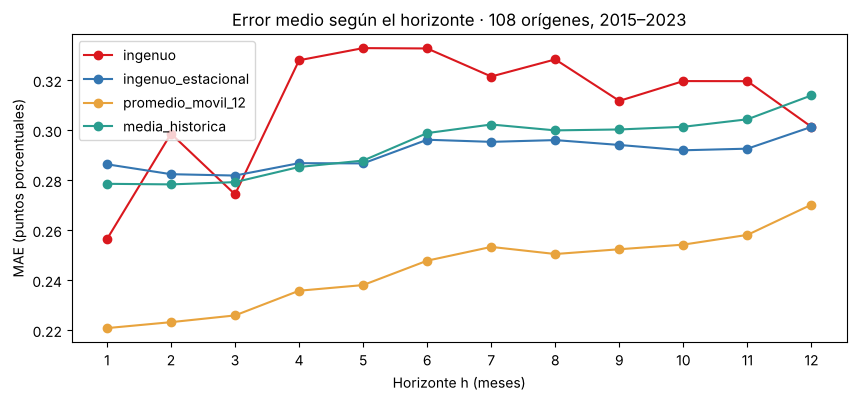

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for m, color in zip(metodos, ['#DA181E', '#3476B1', '#E8A33D', '#2A9D8F']):
    ax.plot(mae_por_horizonte.index, mae_por_horizonte[m], marker='o', label=m, color=color)
ax.set_xlabel('Horizonte h (meses)')
ax.set_ylabel('MAE (puntos porcentuales)')
ax.set_title('Error medio según el horizonte · 108 orígenes, 2015–2023')
ax.set_xticks(range(1, 13))
ax.legend()
plt.show()

### Cómo leer el gráfico

- **El promedio móvil de 12 meses** es el mejor en todos los horizontes (MAE ≈ 0.22 en $h=1$ y ≈ 0.27 en $h=12$).
- **El error sí crece con el horizonte**, pero poco: la inflación mensual es tan ruidosa que incluso el próximo mes es difícil de anticipar.
- **El ingenuo** es competitivo en $h = 1$ pero empeora rápido: copiar el último mes funciona solo si ese mes es representativo.

**Conclusión:** en la inflación mensual el horizonte importa menos que el ruido. En series persistentes (tasa de interés, reservas) la diferencia entre $h = 1$ y $h = 12$ sería mucho mayor.

Fíjate también en otra cosa: con 108 orígenes, **el ganador cambió** respecto al Día 1. Eso nos lleva a la parte 3.

# 3. Validación con origen móvil (1.5)

## 3.1 El problema de un solo corte

El Día 1 decidimos con un solo bloque de 12 meses (2024). Es como juzgar a un estudiante por un solo examen: si ese día estuvo enfermo, la nota no representa lo que sabe. En series de tiempo el "día de enfermedad" fue un año con choques de precios.

## 3.2 La idea del origen móvil

En lugar de un corte, hacemos **muchos**: avanzamos el origen mes a mes, y en cada paso:

1. entrenamos (o calculamos el pronóstico) con todos los datos **hasta el origen**;
2. pronosticamos el horizonte que nos interesa;
3. guardamos el error;
4. movemos el origen un mes y repetimos.

Al final, el error promedio resume **muchos meses distintos**, no solo un año.

### A mano, con una serie de 8 meses

Supongamos los valores $y = [2, 4, 3, 5, 6, 4, 7, 6]$ y el método ingenuo con $h = 1$. Empezamos con 4 meses de historia:

| Paso | Historia (Train) | Origen | Pronóstico ($h=1$) | Real | Error abs. |
|---:|---|---:|---:|---:|---:|
| 1 | 2, 4, 3, 5 | mes 4 | 5 | 6 | 1 |
| 2 | 2, 4, 3, 5, 6 | mes 5 | 6 | 4 | 2 |
| 3 | 2, 4, 3, 5, 6, 4 | mes 6 | 4 | 7 | 3 |
| 4 | 2, 4, 3, 5, 6, 4, 7 | mes 7 | 7 | 6 | 1 |

$$
MAE_{\text{origen móvil}} = \frac{1 + 2 + 3 + 1}{4} = 1.75
$$

Cada fila es un **pliegue** (*fold*). La historia **crece** en cada paso: por eso se llama ventana **expansiva** (*expanding window*). Es la versión temporal del K-Fold del Módulo 3, con una diferencia esencial: **el pliegue de prueba siempre está después del de entrenamiento**.

In [8]:
mini = pd.Series([2, 4, 3, 5, 6, 4, 7, 6], index=pd.period_range('2026-01', periods=8, freq='M'))

errores_mini = []
for fin in range(4, 8):                      # la historia termina en las posiciones 4, 5, 6, 7
    historia = mini.iloc[:fin]
    pronostico = historia.iloc[-1]           # ingenuo
    real = mini.iloc[fin]
    errores_mini.append(abs(real - pronostico))
    print(f'Historia: {historia.tolist()} → pronóstico {pronostico}, real {real}, error {abs(real - pronostico)}')

print('MAE origen móvil:', np.mean(errores_mini))

Historia: [2, 4, 3, 5] → pronóstico 5, real 6, error 1
Historia: [2, 4, 3, 5, 6] → pronóstico 6, real 4, error 2
Historia: [2, 4, 3, 5, 6, 4] → pronóstico 4, real 7, error 3
Historia: [2, 4, 3, 5, 6, 4, 7] → pronóstico 7, real 6, error 1
MAE origen móvil: 1.75


**Qué obtuvimos:** los mismos cuatro pliegues de la tabla y MAE = 1.75.

## 3.3 Origen móvil con sktime

sktime trae esta lógica lista en dos piezas:

**1. `ExpandingWindowSplitter`: define los pliegues.**

| Parámetro | Qué indica | En el ejemplo |
|---|---|---|
| `initial_window` | cuántos meses tiene la primera historia | 4 |
| `step_length` | cuánto avanza el origen en cada pliegue | 1 |
| `fh` | qué horizontes se evalúan | `[1]` |

**2. `evaluate`: aplica un pronosticador en cada pliegue y calcula la métrica.**

| Parámetro | Qué recibe |
|---|---|
| `forecaster` | el pronosticador, por ejemplo `NaiveForecaster(strategy='last')` |
| `cv` | el `ExpandingWindowSplitter` |
| `y` | la serie |
| `scoring` | la métrica, por ejemplo `MeanAbsoluteError()` |

Devuelve una tabla con **una fila por pliegue**.

In [9]:
cv_mini = ExpandingWindowSplitter(initial_window=4, step_length=1, fh=[1])

print('Número de pliegues:', cv_mini.get_n_splits(mini))

resultado_mini = evaluate(
    forecaster=NaiveForecaster(strategy='last'), 
    cv=cv_mini,
    y=mini,
    scoring=MeanAbsoluteError(),
)

resultado_mini[['cutoff', 'len_train_window', 'test_MeanAbsoluteError']]

Número de pliegues: 4


,cutoff,len_train_window,test_MeanAbsoluteError
0,2026-04,4,1.0
1,2026-05,5,2.0
2,2026-06,6,3.0
3,2026-07,7,1.0


**Cómo leer la tabla:**

- `cutoff`: el origen de cada pliegue (abril, mayo, junio y julio de 2026).
- `len_train_window`: cuántos meses de historia tenía (4, 5, 6 y 7: la ventana se expande).
- `test_MeanAbsoluteError`: el error de ese pliegue (1, 2, 3 y 1).

El promedio de la última columna es 1.75, igual que a mano.

## 3.4 Origen móvil sobre la inflación

**Qué vamos a hacer:** usar los datos hasta diciembre de 2023 (Train + Validation del Día 1) y evaluar con origen móvil los cinco métodos simples. La primera historia tendrá 120 meses (2005–2014), así que los pliegues cubren de enero de 2015 a diciembre de 2024: **120 pronósticos** en lugar de 12. Después separaremos 2015–2023 (108 meses) y 2024 (los 12 meses que usamos el Día 1).

El Test (2025–2026) sigue **sin tocarse**. Este bloque tarda unos segundos: son 120 pliegues por cada uno de los 5 métodos.

In [10]:
# Usamos los datos hasta diciembre de 2024 (sin el Test) para comparar con la decisión del Día 1,
# con índice de periodos, como pide sktime.
y_p = y.loc[:'2024-12'].to_period('M')

cv = ExpandingWindowSplitter(initial_window=120, step_length=1, fh=[1])
print('Pliegues:', cv.get_n_splits(y_p))

candidatos = {
    'ingenuo': NaiveForecaster(strategy='last'),
    'ingenuo_estacional': NaiveForecaster(strategy='last', sp=12),
    'promedio_movil_3': NaiveForecaster(strategy='mean', window_length=3),
    'promedio_movil_12': NaiveForecaster(strategy='mean', window_length=12),
    'media_historica': NaiveForecaster(strategy='mean'),
}

resultados_cv = {}
for nombre, pronosticador in candidatos.items():
    r = evaluate(forecaster=pronosticador, cv=cv, y=y_p, scoring=MeanAbsoluteError())
    resultados_cv[nombre] = r.set_index('cutoff')['test_MeanAbsoluteError']

errores_cv = pd.DataFrame(resultados_cv)
# El índice es el origen (cutoff); le sumamos un mes para que sea el mes pronosticado.
errores_cv.index = errores_cv.index.to_timestamp() + pd.DateOffset(months=1)
errores_cv.index.name = 'mes_pronosticado'
errores_cv.tail(3).round(3)

Pliegues: 120


,ingenuo,ingenuo_estacional,promedio_movil_3,promedio_movil_12,media_historica
mes_pronosticado,,,,,
2024-10-01,0.415,0.063,0.679,0.358,0.464
2024-11-01,0.018,0.143,0.307,0.370,0.479
2024-12-01,0.730,0.962,0.880,1.112,1.207


**Qué obtuvimos:** una tabla con 120 filas (de enero 2015 a diciembre 2024), una por mes pronosticado, y el error absoluto de cada método en ese mes. Ahora podemos resumirla de dos maneras.

In [11]:
resumen_cv = pd.DataFrame({
    'MAE_2015_2023': errores_cv.loc[:'2023'].mean(),     # 108 pliegues
    'MAE_solo_2024': errores_cv.loc['2024'].mean(),      # los 12 meses del Día 1
})
resumen_cv['ranking_2015_2023'] = resumen_cv['MAE_2015_2023'].rank().astype(int)
resumen_cv['ranking_solo_2024'] = resumen_cv['MAE_solo_2024'].rank().astype(int)
resumen_cv.sort_values('MAE_2015_2023').round(3)

,MAE_2015_2023,MAE_solo_2024,ranking_2015_2023,ranking_solo_2024
promedio_movil_12,0.223,0.472,1,2
promedio_movil_3,0.234,0.588,2,4
ingenuo,0.259,0.615,3,5
media_historica,0.280,0.482,4,3
ingenuo_estacional,0.288,0.408,5,1


### Dos decisiones distintas con los mismos métodos

| Validación | Pronósticos evaluados | Ganador |
|---|---:|---|
| Un solo corte (2024) | 12 | ingenuo estacional |
| Origen móvil (2015–2023) | 108 | **promedio móvil de 12** |

El ingenuo estacional, primero en 2024, es de los peores cuando se miran nueve años. Y el promedio móvil de 12, ganador con origen móvil, fue también de los mejores en el Test del Día 1 (con $k = 14$, MAE ≈ 0.29). **El origen móvil eligió mejor.**

Miremos cómo cambia el ranking año por año.

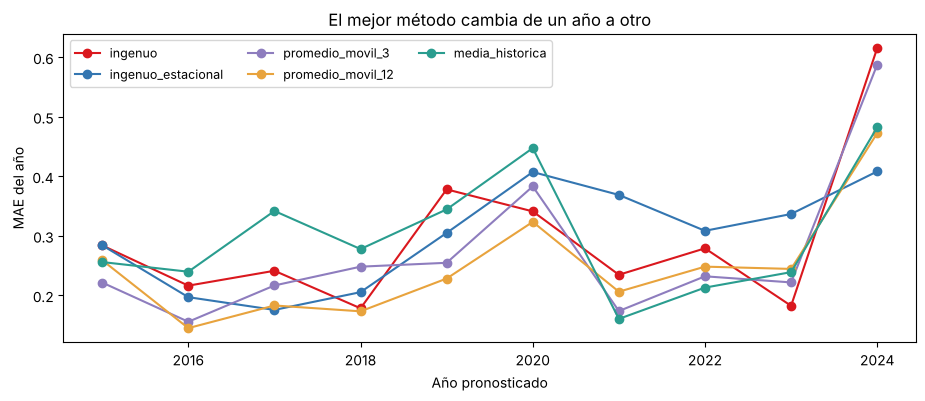

Ganador de cada año:
mes_pronosticado
2015      promedio_movil_3
2016     promedio_movil_12
2017    ingenuo_estacional
2018     promedio_movil_12
2019     promedio_movil_12
2020     promedio_movil_12
2021       media_historica
2022       media_historica
2023               ingenuo
2024    ingenuo_estacional


In [12]:
mae_anual = errores_cv.groupby(errores_cv.index.year).mean()

fig, ax = plt.subplots(figsize=(11, 4))
for m, color in zip(mae_anual.columns, ['#DA181E', '#3476B1', '#8E7DBE', '#E8A33D', '#2A9D8F']):
    ax.plot(mae_anual.index, mae_anual[m], marker='o', label=m, color=color)
ax.set_xlabel('Año pronosticado')
ax.set_ylabel('MAE del año')
ax.set_title('El mejor método cambia de un año a otro')
ax.legend(ncol=3, fontsize=9)
plt.show()

print('Ganador de cada año:')
print(mae_anual.idxmin(axis=1).to_string())

**Lectura:** el ganador cambia de año en año, y 2024 tiene errores mucho mayores que los demás para todos los métodos. **Un solo año dice poco; muchos años juntos dicen bastante más.** Por eso, desde hoy, validaremos siempre con origen móvil.

### Cuándo usar cada esquema

| Esquema | Ventaja | Desventaja |
|---|---|---|
| Un corte (Train / Validation / Test) | rápido, fácil de explicar | depende de un solo periodo |
| Origen móvil con ventana expansiva | usa muchos periodos; decisión más estable | más lento: un ajuste por pliegue |
| Origen móvil con ventana fija (`SlidingWindowSplitter`) | olvida el pasado lejano | menos datos en cada ajuste |

**El Test sigue siendo sagrado:** el origen móvil reemplaza a la Validation, no al Test.

# 4. Estacionariedad (2.2)

## 4.1 ¿Qué es una serie estacionaria?

Una serie es **estacionaria** cuando su comportamiento estadístico **no cambia con el tiempo**:

1. su **media** es la misma en cualquier periodo;
2. su **varianza** (dispersión) es la misma en cualquier periodo;
3. la relación entre dos meses depende solo de **cuántos meses los separan**, no de en qué año están.

**¿Por qué importa?** Los modelos AR, MA y ARIMA aprenden relaciones del pasado (por ejemplo, "este mes se parece 0.48 veces al anterior"). Si la serie cambia de comportamiento, lo aprendido en 2010 no sirve para 2026. **Estacionariedad significa que el pasado es una buena guía del futuro.**

| Serie | ¿Estacionaria? | Por qué |
|---|---|---|
| IPC (índice) | **no** | sube casi siempre: su media de 2005–2012 es muy distinta de la de 2021–2026 |
| Inflación mensual | **aproximadamente** | oscila alrededor de un nivel bajo, aunque ese nivel cambia por etapas |
| Exportaciones (nivel) | **no** | crecen con la economía |
| Variación de las exportaciones | **sí, probablemente** | oscila alrededor de cero |

## 4.2 Reconocerla en un gráfico: media y desviación móviles

**Qué vamos a hacer:** dibujar el IPC (índice) y la inflación mensual con su media y su desviación estándar móviles de 24 meses. Si la serie es estacionaria, ambas líneas deberían ser aproximadamente planas.

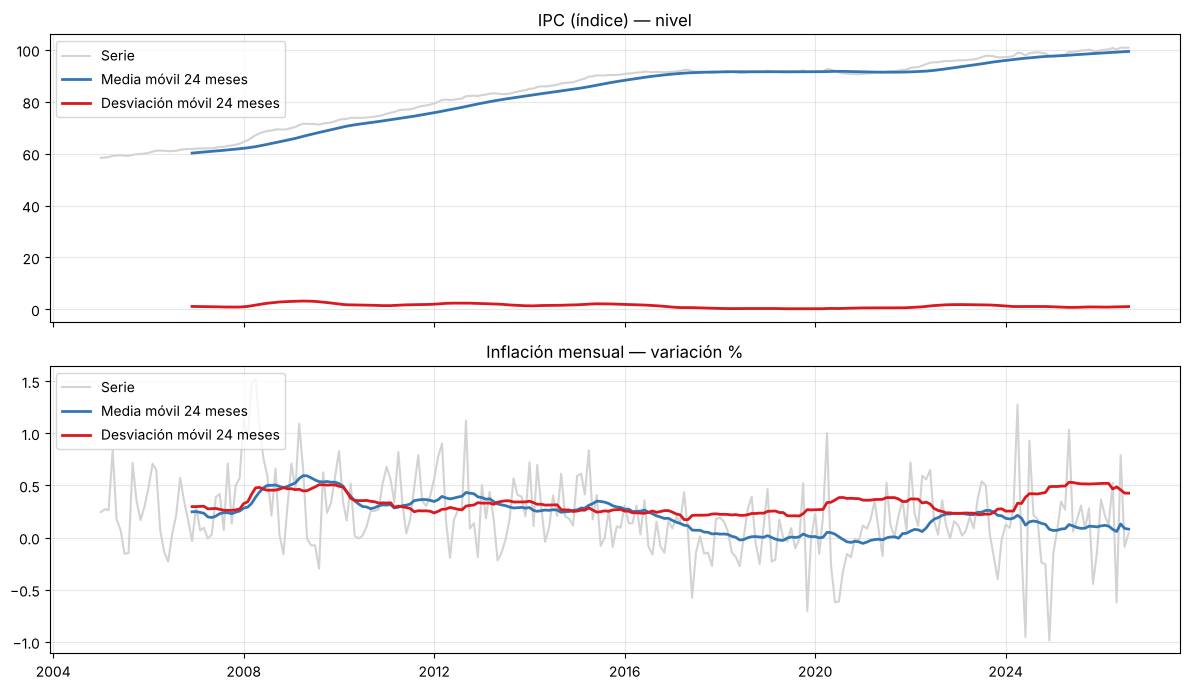

In [13]:
indice = series['ipc_indice'].loc['2005':].dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, s, titulo in zip(axes, [indice, y], ['IPC (índice) — nivel', 'Inflación mensual — variación %']):
    ax.plot(s, color='lightgray', label='Serie')
    ax.plot(s.rolling(24).mean(), color='#3476B1', linewidth=2, label='Media móvil 24 meses')
    ax.plot(s.rolling(24).std(), color='#DA181E', linewidth=2, label='Desviación móvil 24 meses')
    ax.set_title(titulo)
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Lectura

- **IPC (arriba):** la media móvil sube durante 20 años, de ≈ 60 a ≈ 100. **No es estacionaria**: no existe "un nivel típico" del índice.
- **Inflación (abajo):** la media móvil se mueve dentro de una franja estrecha (entre ≈ −0.06 y ≈ 0.59 %) y la desviación se mantiene entre ≈ 0.17 y ≈ 0.53. **Es aproximadamente estacionaria**, aunque su nivel cambia por etapas.

Comprobémoslo con números: media y desviación en tres periodos.

In [14]:
periodos = {'2005–2012': ('2005', '2012'), '2013–2020': ('2013', '2020'), '2021–2026': ('2021', '2026')}

pd.DataFrame({
    nombre: {
        'media_IPC_indice': indice.loc[a:b].mean(),
        'media_inflacion': y.loc[a:b].mean(),
        'desv_inflacion': y.loc[a:b].std(),
    }
    for nombre, (a, b) in periodos.items()
}).round(2)

,2005–2012,2013–2020,2021–2026
media_IPC_indice,69.29,89.61,96.56
media_inflacion,0.36,0.10,0.16
desv_inflacion,0.37,0.31,0.38


**Qué obtuvimos:** la media del índice pasa de ≈ 69 a ≈ 97: cambia muchísimo. La media de la inflación va de 0.36 a 0.10 y a 0.16; cambia, pero en una escala mucho menor. La desviación de la inflación es parecida en los tres periodos (≈ 0.31 a 0.38).

## 4.3 Diferenciación: la herramienta para volver estacionaria una serie

**Diferenciar** es restar a cada valor el valor anterior (Día 0):

$$
\Delta y_t = y_t - y_{t-1}
$$

Si una serie sube de forma sostenida, sus diferencias oscilan alrededor de la subida promedio: se elimina la tendencia.

### A mano

| Mes | Índice | $\Delta$ (diferencia) |
|---|---:|---:|
| 1 | 100 | — |
| 2 | 102 | 2 |
| 3 | 103 | 1 |
| 4 | 105 | 2 |
| 5 | 106 | 1 |

El índice sube sin parar; sus diferencias oscilan entre 1 y 2. **Una diferencia convirtió una serie con tendencia en una serie estable.**

Tipos de diferencia:

| Diferencia | Fórmula | En Pandas | Elimina |
|---|---|---|---|
| Ordinaria (orden 1) | $y_t - y_{t-1}$ | `diff()` | tendencia |
| Ordinaria de orden 2 | diferenciar la diferencia | `diff().diff()` | tendencia que se acelera |
| **Estacional** | $y_t - y_{t-12}$ | `diff(12)` | estacionalidad |

> **Relación con la inflación:** la inflación mensual es, prácticamente, la diferencia del logaritmo del IPC ($\Delta \log IPC_t \times 100$). Por eso es más estacionaria que el índice: **el INEC ya la diferenció por nosotros.**

**Qué vamos a hacer:** diferenciar el índice y comparar los gráficos antes y después.

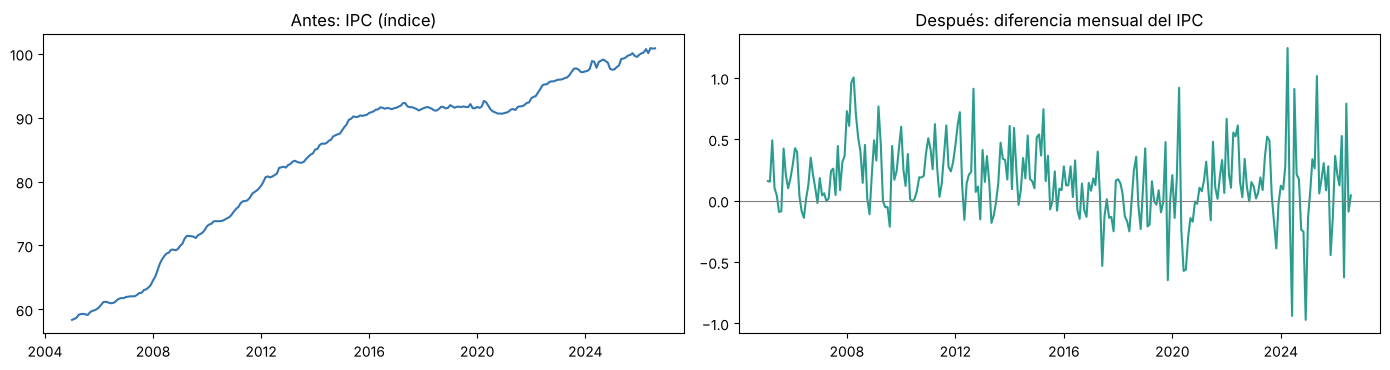

Primeros valores diferenciados: [0.159, 0.154, 0.491]


In [15]:
indice_diferenciado = indice.diff()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(indice, color='#3476B1')
axes[0].set_title('Antes: IPC (índice)')
axes[1].plot(indice_diferenciado, color='#2A9D8F')
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set_title('Después: diferencia mensual del IPC')
plt.tight_layout()
plt.show()

print('Primeros valores diferenciados:', indice_diferenciado.dropna().head(3).round(3).tolist())

**Lectura:** el índice tiene una subida clara; su diferencia oscila alrededor de un nivel bajo, como la inflación. El primer valor queda vacío (`NaN`): no hay mes anterior al primero. **Cada diferencia cuesta una observación** (la estacional cuesta 12).

### No hay que diferenciar de más

Si diferenciamos una serie que ya es estacionaria, la volvemos más ruidosa y le creamos una autocorrelación negativa artificial. Por eso necesitamos una prueba formal antes de decidir.

# 5. Prueba ADF: ¿es estacionaria? (2.2)

## 5.1 La idea

La **prueba de Dickey-Fuller aumentada (ADF)** pregunta si la serie tiene una **raíz unitaria**, que es la forma técnica de decir "no regresa a un nivel medio: cada choque la desplaza de forma permanente".

La prueba estima una regresión de la diferencia contra el nivel anterior:

$$
\Delta y_t = \alpha + \gamma\, y_{t-1} + \text{(rezagos de } \Delta y \text{)} + \varepsilon_t
$$

- Si $\gamma = 0$: el cambio de hoy no depende del nivel de ayer → la serie **no vuelve** a su media → **no estacionaria**.
- Si $\gamma < 0$: cuando la serie está alta, tiende a bajar, y viceversa → **vuelve** a su media → **estacionaria**.

## 5.2 Hipótesis y decisión

| | Enunciado |
|---|---|
| $H_0$ (nula) | la serie tiene raíz unitaria: **no es estacionaria** |
| $H_1$ (alternativa) | la serie **es estacionaria** |

**Regla de decisión** (con nivel de significancia 5 %):

- **p-valor < 0.05** → rechazamos $H_0$ → hay evidencia de que la serie **es estacionaria**;
- **p-valor ≥ 0.05** → no rechazamos $H_0$ → no hay evidencia suficiente: la tratamos como **no estacionaria** y probamos diferenciarla.

Equivalentemente: si el **estadístico ADF** es **más negativo** que el valor crítico al 5 %, la serie es estacionaria.

## 5.3 `adfuller` de statsmodels

| Parámetro | Qué indica | Valor que usamos |
|---|---|---|
| `x` | la serie | — |
| `autolag` | cómo elegir cuántos rezagos de $\Delta y$ incluir | `'AIC'` (por defecto) |
| `regression` | términos deterministas: `'c'` constante, `'ct'` constante y tendencia | `'c'` |

Devuelve una **tupla**; las posiciones que nos interesan:

| Posición | Contenido |
|---|---|
| `[0]` | estadístico ADF |
| `[1]` | p-valor |
| `[2]` | rezagos usados |
| `[4]` | diccionario de valores críticos (1 %, 5 %, 10 %) |

**Qué vamos a hacer:** aplicarla al índice del IPC y leer cada pieza del resultado.

In [16]:
# result_object=False: devuelve la tupla clásica (y evita un aviso de statsmodels).
resultado = adfuller(indice, autolag='AIC')

print('Tipo de resultado:', type(resultado).__name__)
print('Estadístico ADF:', round(resultado[0], 3))
print('p-valor:', round(resultado[1], 4))
print('Rezagos usados:', resultado[2])
print('Valores críticos:', {k: round(v, 2) for k, v in resultado[4].items()})

Tipo de resultado: tuple
Estadístico ADF: -1.903
p-valor: 0.3305
Rezagos usados: 14
Valores críticos: {'1%': np.float64(-3.46), '5%': np.float64(-2.87), '10%': np.float64(-2.57)}


/tmp/ipykernel_461/2143629171.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(indice, autolag='AIC')


**Cómo leerlo:** el estadístico (≈ −1.9) **no** es más negativo que el valor crítico al 5 % (≈ −2.87), y el p-valor (≈ 0.33) es mayor que 0.05. **No rechazamos $H_0$: el IPC no es estacionario.** Coincide con el gráfico.

Escribamos una función para aplicar la prueba a varias series y leerla en una tabla.

In [17]:
def prueba_adf(serie, nombre, autolag='AIC'):
    estadistico, p_valor, rezagos, n_obs, criticos, _ = adfuller(serie.dropna(), autolag=autolag)
    return {
        'serie': nombre,
        'estadistico': round(estadistico, 2),
        'critico_5%': round(criticos['5%'], 2),
        'p_valor': round(p_valor, 4),
        'rezagos': rezagos,
        'conclusion': 'estacionaria' if p_valor < 0.05 else 'NO estacionaria',
    }

exportaciones = series['exportaciones_fob_musd'].loc['2005':].dropna()

pd.DataFrame([
    prueba_adf(indice, 'IPC índice'),
    prueba_adf(indice.diff(), 'IPC índice diferenciado'),
    prueba_adf(exportaciones, 'Exportaciones (nivel)'),
    prueba_adf(exportaciones.diff(), 'Exportaciones diferenciadas'),
    prueba_adf(y, 'Inflación mensual · rezagos por AIC'),
    prueba_adf(y, 'Inflación mensual · rezagos por BIC', autolag='BIC'),
]).set_index('serie')

/tmp/ipykernel_461/1898740603.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estadistico, p_valor, rezagos, n_obs, criticos, _ = adfuller(serie.dropna(), autolag=autolag)
/tmp/ipykernel_461/1898740603.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estadistico, p_valor, rezagos, n_obs, criticos, _ = adfuller(serie.dropna(), autolag=autolag)
/tmp/ipykernel_461/189

,estadistico,critico_5%,p_valor,rezagos,conclusion
serie,,,,,
IPC índice,-1.90,-2.87,0.3305,14,NO estacionaria
IPC índice diferenciado,-2.73,-2.87,0.0696,13,NO estacionaria
Exportaciones (nivel),-1.03,-2.87,0.7434,1,NO estacionaria
Exportaciones diferenciadas,-14.69,-2.87,0.0000,1,estacionaria
Inflación mensual · rezagos por AIC,-2.77,-2.87,0.0624,13,NO estacionaria
Inflación mensual · rezagos por BIC,-10.95,-2.87,0.0000,0,estacionaria


### Qué nos dice la tabla

| Serie | Resultado | Decisión |
|---|---|---|
| IPC índice | no estacionario | hay que diferenciar ($d = 1$) |
| IPC diferenciado | cerca del límite (p ≈ 0.07) | la diferencia casi basta |
| Exportaciones (nivel) | no estacionaria | hay que diferenciar |
| Exportaciones diferenciadas | claramente estacionaria | $d = 1$ es suficiente |
| **Inflación mensual** | **depende de cuántos rezagos use la prueba** | ver abajo |

### El caso de la inflación: una prueba no es una sentencia

Con rezagos elegidos por **AIC** (13 rezagos), el p-valor es ≈ 0.06: justo por encima de 0.05. Con **BIC** (0 rezagos), el p-valor es prácticamente cero: claramente estacionaria.

¿Por qué? Con muchos rezagos, la prueba pierde potencia; la estacionalidad de la inflación hace que AIC elija muchos. La lectura sensata, uniendo la prueba con el gráfico de la parte 4:

> La inflación mensual **es estacionaria alrededor de un nivel que cambia por etapas**. No necesita diferenciarse ($d = 0$), pero conviene comprobarlo comparando modelos con $d = 0$ y $d = 1$ en el Día 3.

**Regla práctica:** no decidas solo con el p-valor. Mira el gráfico, prueba con distintos rezagos y, si hay duda, compara los dos modelos con origen móvil.

# 6. Modelos AR y MA (2.1)

## 6.1 El modelo autorregresivo AR(1)

Un modelo **autorregresivo de orden 1**, AR(1), dice que el valor de este mes depende del valor del mes anterior más un choque:

$$
y_t = c + \phi\, y_{t-1} + \varepsilon_t
$$

| Símbolo | Nombre | Significado |
|---|---|---|
| $c$ | constante | nivel de base |
| $\phi$ (phi) | coeficiente autorregresivo | cuánto "pasa" del mes anterior a este |
| $\varepsilon_t$ | choque o error | lo impredecible de este mes |

**Cómo leer $\phi$:**

- $\phi = 0$: el pasado no importa (ruido puro alrededor de $c$).
- $\phi = 0.5$: la mitad de una desviación del mes pasado se mantiene este mes.
- $\phi$ cercano a 1: la serie es muy persistente.
- $\phi = 1$: raíz unitaria; la serie no vuelve a su media (no estacionaria).

**La media de largo plazo** de un AR(1) estacionario es:

$$
\mu = \frac{c}{1 - \phi}
$$

### Pronóstico a mano

Supón que $c = 0.12$ y $\phi = 0.48$, y que el último mes tuvo una inflación de $y_t = -0.02$:

$$
\hat y_{t+1} = 0.12 + 0.48 \times (-0.02) = 0.11
$$

$$
\hat y_{t+2} = 0.12 + 0.48 \times 0.11 = 0.17
$$

$$
\mu = \frac{0.12}{1 - 0.48} = 0.23
$$

El pronóstico **se acerca poco a poco a la media de largo plazo**: el AR(1) recuerda el último mes, pero ese recuerdo se desvanece. Está a medio camino entre el ingenuo (que solo recuerda el último mes) y la media histórica (que no recuerda nada).

## 6.2 Estimar un AR(1) a mano: es una regresión

El AR(1) es una **regresión lineal simple** del Módulo 3: $X$ = inflación del mes anterior, $y$ = inflación de este mes. Las fórmulas de pendiente e intercepto son las mismas:

$$
\phi = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2} \qquad c = \bar y - \phi\,\bar x
$$

**Qué vamos a hacer:** estimarlo con esas fórmulas usando los datos hasta diciembre de 2023.

In [18]:
train = y.loc[:'2023-12']

x_anterior = train.shift(1).dropna()     # X: el mes anterior
y_actual = train.loc[x_anterior.index]   # y: el mes actual

phi_mano = np.sum((x_anterior - x_anterior.mean()) * (y_actual - y_actual.mean())) / np.sum((x_anterior - x_anterior.mean()) ** 2)
c_mano = y_actual.mean() - phi_mano * x_anterior.mean()

print(f'phi (a mano) = {phi_mano:.4f}')
print(f'c   (a mano) = {c_mano:.4f}')
print(f'media de largo plazo c / (1 - phi) = {c_mano / (1 - phi_mano):.3f}')

phi (a mano) = 0.4770
c   (a mano) = 0.1173
media de largo plazo c / (1 - phi) = 0.224


**Qué obtuvimos:** $\phi \approx 0.48$ y $c \approx 0.12$, los valores del ejemplo. La media de largo plazo es ≈ 0.22 %, muy cerca de la media de la serie.

## 6.3 El mismo AR(1) con statsmodels: `AutoReg`

`AutoReg` sigue el patrón **crear → `fit()` → consultar**.

| Parámetro | Qué indica |
|---|---|
| `endog` | la serie |
| `lags` | cuántos rezagos (el orden $p$) |
| `trend` | `'c'` incluye constante (por defecto) |

| Atributo del resultado | Contenido |
|---|---|
| `.params` | $c$ y $\phi$ |
| `.summary()` | tabla con coeficientes, errores estándar y p-valores |
| `.predict(start, end)` | pronósticos |

In [19]:
modelo_ar1 = AutoReg(train, lags=1)     # 1. crear con los datos
resultado_ar1 = modelo_ar1.fit()        # 2. estimar

print(resultado_ar1.params.round(4))    # 3. consultar

const                 0.1173
ipc_var_mensual.L1    0.4770
dtype: float64


**Coincide con el cálculo a mano.** Veamos el resumen estadístico, que es lo que statsmodels agrega frente a scikit-learn.

In [20]:
print(resultado_ar1.summary().tables[1])

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.1173      0.024      4.848      0.000       0.070       0.165
ipc_var_mensual.L1     0.4770      0.058      8.165      0.000       0.362       0.591


### Cómo leer la tabla de coeficientes

| Columna | Significado | Lectura para $\phi$ (`ipc_var_mensual.L1`) |
|---|---|---|
| `coef` | el valor estimado | 0.48 |
| `std err` | incertidumbre de la estimación | ≈ 0.06 |
| `z` | coeficiente / error estándar | ≈ 8: muy lejos de cero |
| `P>|z|` | p-valor de $H_0$: coeficiente = 0 | ≈ 0: el rezago **sí** es significativo |
| `[0.025 0.975]` | intervalo de confianza al 95 % | $\phi$ está entre ≈ 0.36 y ≈ 0.59 |

**Interpretación económica:** de una desviación de la inflación respecto a su media, aproximadamente la mitad se mantiene al mes siguiente. Hay persistencia, pero se disipa rápido.

### Pronóstico con el AR(1)

**Qué vamos a hacer:** pronosticar enero a marzo de 2024 desde diciembre de 2023 y compararlo con el cálculo a mano.

In [21]:
pron_ar1 = resultado_ar1.predict(start='2024-01-01', end='2024-03-01')

print('Último dato (dic 2023):', round(train.iloc[-1], 3))
print(pron_ar1.round(3).to_string())

Último dato (dic 2023): -0.023
2024-01-01    0.106
2024-02-01    0.168
2024-03-01    0.197
Freq: MS


Enero ≈ 0.106, febrero ≈ 0.168, marzo ≈ 0.197: el pronóstico sube desde −0.02 hacia la media de largo plazo (≈ 0.22), como en el ejemplo a mano.

## 6.4 El modelo de medias móviles MA(1)

El nombre confunde: **no tiene nada que ver con el promedio móvil del Día 1**. Un MA(1) dice que este mes depende del **choque** del mes anterior:

$$
y_t = \mu + \varepsilon_t + \theta\, \varepsilon_{t-1}
$$

| Símbolo | Significado |
|---|---|
| $\mu$ | media de la serie |
| $\varepsilon_t$ | choque de este mes |
| $\theta$ (theta) | cuánto del choque del mes pasado sigue presente |

**La diferencia con AR:**

- En un **AR**, un choque se transmite **para siempre**, cada vez más débil (porque cada mes depende del anterior, que dependía del anterior…).
- En un **MA(1)**, un choque dura **exactamente un mes más** y desaparece.

**Ejemplo económico:** un feriado largo eleva los precios de transporte este mes ($\varepsilon_t$) y deja un efecto residual el mes siguiente ($\theta\,\varepsilon_{t-1}$). Después, nada.

### A mano

Con $\mu = 0.2$, $\theta = 0.5$ y estos choques:

| Mes | Choque $\varepsilon_t$ | $y_t = 0.2 + \varepsilon_t + 0.5\,\varepsilon_{t-1}$ |
|---:|---:|---|
| 1 | 0.0 | 0.2 + 0 + 0 = 0.20 |
| 2 | **1.0** | 0.2 + 1.0 + 0.5(0) = 1.20 |
| 3 | 0.0 | 0.2 + 0 + 0.5(1.0) = **0.70** |
| 4 | 0.0 | 0.2 + 0 + 0.5(0) = **0.20** |

El choque del mes 2 deja medio punto en el mes 3 y desaparece en el mes 4.

## 6.5 Reconocer AR y MA: ACF y PACF

Para saber si una serie se comporta como AR o como MA usamos dos gráficos:

- **ACF** (Día 1): la correlación de $y_t$ con $y_{t-k}$.
- **PACF** (*autocorrelación parcial*): la correlación de $y_t$ con $y_{t-k}$ **descontando** el efecto de los rezagos intermedios. Por ejemplo, la PACF de rezago 2 mide cuánto aporta $y_{t-2}$ **después** de saber $y_{t-1}$.

**La regla para identificar:**

| Modelo | ACF | PACF |
|---|---|---|
| **AR($p$)** | decae poco a poco | **se corta** después del rezago $p$ |
| **MA($q$)** | **se corta** después del rezago $q$ | decae poco a poco |
| ARMA($p$, $q$) | decae | decae |

### Verlo con series simuladas

Para aprender a leer los gráficos, **simulamos** series con parámetros que conocemos. `ArmaProcess` crea un proceso a partir de sus coeficientes:

- `ar=[1, -φ]`: el signo menos es una convención de statsmodels (escribe el modelo como $y_t - \phi y_{t-1} = \varepsilon_t$);
- `ma=[1, θ]`;
- `.generate_sample(nsample=n)` genera $n$ observaciones.

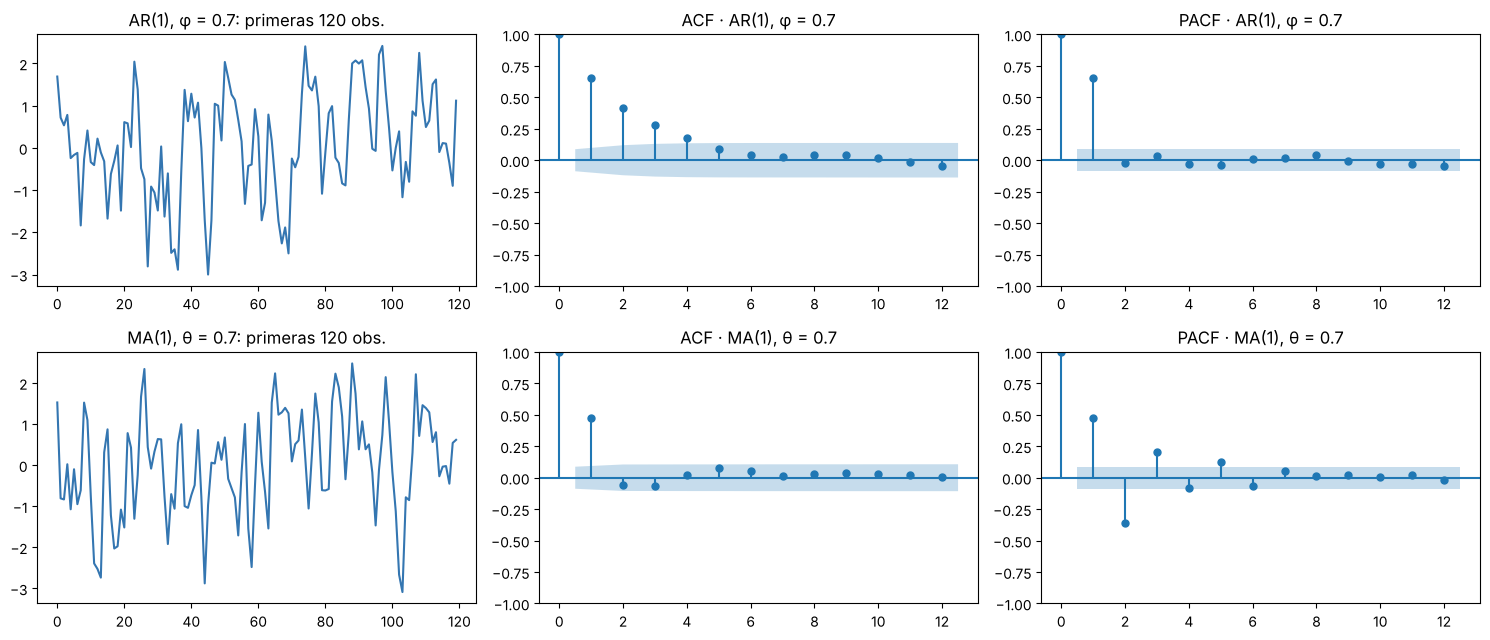

In [22]:
np.random.seed(7)
n_sim = 500

ar1_simulado = ArmaProcess(ar=[1, -0.7], ma=[1]).generate_sample(nsample=n_sim)   # AR(1) con phi = 0.7
ma1_simulado = ArmaProcess(ar=[1], ma=[1, 0.7]).generate_sample(nsample=n_sim)    # MA(1) con theta = 0.7

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for fila, (serie_sim, nombre) in enumerate([(ar1_simulado, 'AR(1), φ = 0.7'), (ma1_simulado, 'MA(1), θ = 0.7')]):
    axes[fila, 0].plot(serie_sim[:120], color='#3476B1')
    axes[fila, 0].set_title(f'{nombre}: primeras 120 obs.')
    plot_acf(serie_sim, lags=12, ax=axes[fila, 1], title=f'ACF · {nombre}')
    plot_pacf(serie_sim, lags=12, ax=axes[fila, 2], title=f'PACF · {nombre}', method='ywm')
plt.tight_layout()
plt.show()

### Lectura de los gráficos simulados

- **AR(1), fila de arriba:** la ACF **decae poco a poco** (0.7, 0.49, 0.34…, es decir $\phi^k$); la PACF tiene **un solo bastón** grande en el rezago 1 y luego se corta. → "PACF se corta en 1" = AR(1).
- **MA(1), fila de abajo:** la ACF tiene **un solo bastón** en el rezago 1 y se corta; la PACF decae alternando signos. → "ACF se corta en 1" = MA(1).

## 6.6 ACF y PACF de la inflación

**Qué vamos a hacer:** aplicar la misma lectura a la serie real.

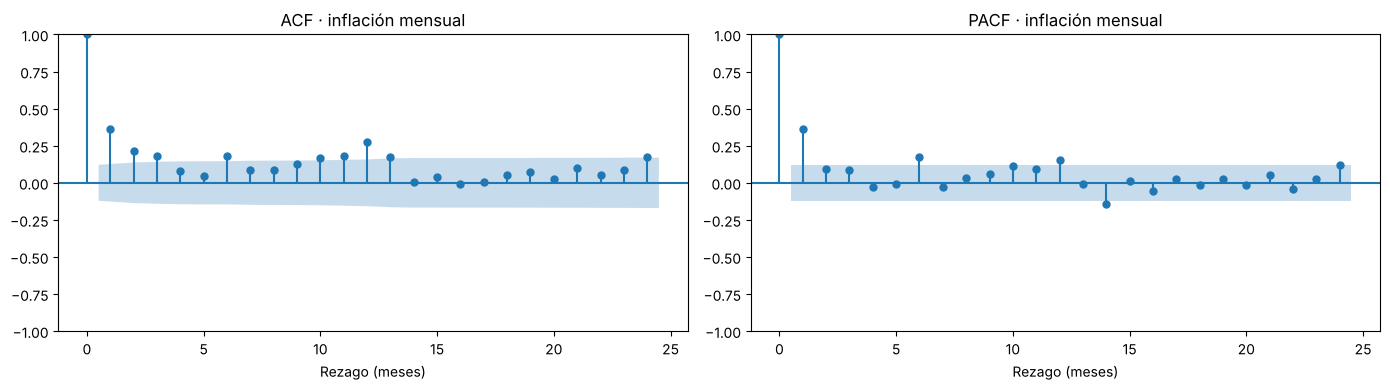

PACF rezagos 1 a 13: [ 0.36  0.09  0.09 -0.03 -0.01  0.17 -0.03  0.03  0.06  0.12  0.09  0.15
 -0.01]


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=24, ax=axes[0], title='ACF · inflación mensual')
plot_pacf(y, lags=24, ax=axes[1], title='PACF · inflación mensual', method='ywm')
for ax in axes:
    ax.set_xlabel('Rezago (meses)')
plt.tight_layout()
plt.show()

print('PACF rezagos 1 a 13:', pacf(y, nlags=13, method='ywm')[1:].round(2))

### Interpretación

- **PACF:** un bastón claro en el rezago 1 (≈ 0.36); los rezagos 2 a 5 caen dentro de la banda. Esto sugiere un **AR(1)**.
- **ACF:** decae de forma gradual en los primeros rezagos, coherente con un AR.
- **Rezago 12:** sobresale en ambas, y también el 6 en la PACF. Es la **estacionalidad**: un AR(1) simple no la captura.

**Candidatos para el Día 3:** un ARIMA(1, 0, 0) como base, y una versión **estacional** que agregue un término en el rezago 12.

> En series reales la lectura casi nunca es tan limpia como en las simuladas. La ACF y la PACF **proponen** candidatos; la validación con origen móvil **decide**.

# 7. Componentes de ARIMA y SARIMA (2.3)

## 7.1 ARIMA($p$, $d$, $q$)

**ARIMA** junta las tres piezas del día:

| Letra | Nombre | Pieza | Cómo se elige |
|---|---|---|---|
| **AR** → $p$ | autorregresivo | rezagos de la serie | PACF se corta en $p$ |
| **I** → $d$ | integrado | número de diferencias | prueba ADF y gráfico |
| **MA** → $q$ | medias móviles | rezagos de los choques | ACF se corta en $q$ |

Ejemplos de lectura:

| Modelo | Significado |
|---|---|
| ARIMA(1, 0, 0) | AR(1) sobre la serie sin diferenciar |
| ARIMA(0, 1, 0) | la diferencia es ruido: equivale al **pronóstico ingenuo** |
| ARIMA(1, 1, 1) | se diferencia una vez y se modela con un AR(1) y un MA(1) |
| ARIMA(0, 0, 0) con constante | ruido alrededor de una media: equivale a la **media histórica** |

Los pronósticos simples del Día 1 son casos particulares de ARIMA: por eso son una buena línea base.

## 7.2 SARIMA($p$, $d$, $q$)($P$, $D$, $Q$)$_s$

Cuando hay estacionalidad, se agrega una segunda parte **en el rezago estacional** $s$:

| Parámetro | Qué hace | Ejemplo con $s = 12$ |
|---|---|---|
| $P$ | AR estacional | relaciona enero con el enero anterior |
| $D$ | diferencia estacional | $y_t - y_{t-12}$ |
| $Q$ | MA estacional | choque de hace 12 meses |
| $s$ | longitud de la estación | 12 en datos mensuales |

**Ejemplo:** SARIMA(1, 0, 0)(1, 0, 0)$_{12}$ dice que la inflación de este mes depende de la del **mes anterior** y de la del **mismo mes del año anterior**. Es la combinación natural de los dos bastones que vimos en la PACF (rezagos 1 y 12).

## 7.3 Resumen de candidatos para la inflación

| Evidencia | Decisión |
|---|---|
| ADF y gráfico: aproximadamente estacionaria | $d = 0$ (y probar $d = 1$ como alternativa) |
| PACF se corta en 1 | $p = 1$ |
| Bastones en el rezago 12 | $P = 1$, $s = 12$ |
| ACF sin un corte claro | $q = 0$ como punto de partida |

El Día 3 estimaremos estos modelos, leeremos sus resultados y compararemos sus pronósticos con origen móvil contra la línea base.

# 8. Actividad 1 · ¿Qué nos dicen los datos? (20 puntos)

**Trabajo individual · 30 minutos · sin programación.** El docente entregará una gráfica de inflación mensual y un formulario de cinco preguntas:

1. ¿Existe una tendencia identificable?
2. ¿Se observa estacionalidad o la información es insuficiente?
3. ¿Qué valor pronosticarías usando el último dato?
4. ¿Qué pronóstico obtienes con un promedio móvil de tres periodos?
5. ¿Por qué no conviene separar aleatoriamente los datos temporales?

Todo lo necesario está en los Días 1 y 2: tendencia y estacionalidad (Día 1, parte 3), pronóstico ingenuo y promedio móvil a mano (Día 1, parte 6) y validación cronológica (hoy, parte 3). La rúbrica está en el instrumento de evaluación.

# 9. Reto de cierre: exportaciones

Repite el procedimiento del día con `exportaciones_fob_musd` desde 2005:

1. Grafica la serie con su media y desviación móviles. ¿Parece estacionaria?
2. Aplica la prueba ADF al nivel, a la diferencia y a la diferencia del logaritmo (`np.log(serie).diff()`). ¿Cuántas diferencias necesita?
3. Dibuja la ACF y la PACF de la serie que resultó estacionaria. ¿Qué modelo AR o MA sugieren?
4. Evalúa con origen móvil (primera ventana de 120 meses, $h = 1$) el ingenuo, el ingenuo estacional y el promedio móvil de 3 y de 12. ¿Cuál gana? ¿Coincide con lo que viste el Día 1?
5. Propón un ARIMA o SARIMA candidato y justifica cada parámetro.

In [24]:
# Punto de partida del reto.
exportaciones = series['exportaciones_fob_musd'].loc['2005':].dropna()
print(f'{len(exportaciones)} meses · última observación: {exportaciones.index.max():%b %Y}')
exportaciones.tail(3)

260 meses · última observación: Aug 2026


fecha
2026-06-01    3283.563806
2026-07-01    3717.921551
2026-08-01    3509.096599
Freq: MS, Name: exportaciones_fob_musd, dtype: float64

In [25]:
# A partir de aquí escribe tus propias celdas.

## Checklist del día

- [ ] ¿Sé cuál es el origen y el horizonte de cada pronóstico que hago?
- [ ] ¿Validé con origen móvil y no con un solo corte?
- [ ] ¿Revisé la estacionariedad con un gráfico de media y desviación móviles?
- [ ] ¿Apliqué la prueba ADF e interpreté el p-valor sin tomarlo como sentencia?
- [ ] ¿Diferencié solo lo necesario?
- [ ] ¿Leí la ACF y la PACF para proponer $p$ y $q$?
- [ ] ¿Puedo escribir mi modelo candidato como ARIMA($p$, $d$, $q$)($P$, $D$, $Q$)$_s$ y explicar cada número?

**Puente hacia el Día 3:** ya tenemos candidatos. Mañana los estimaremos con `ARIMA` de statsmodels, revisaremos sus residuos, construiremos intervalos de predicción y los compararemos con la línea base.